<a href="https://colab.research.google.com/github/Mounir04-04/Market-Analysis-and-Stock-Segmentation-Using-RFM/blob/main/w2064549.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6BUIS017W Coursework 1 - Market Analysis and Stock Segmentation Using RFM


In [3]:
# Setup: import the libraries
# Import all required libraries
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Setup: record the Python and package versions
import platform
from importlib.metadata import version, PackageNotFoundError

package_versions = {}
for package in ["numpy", "pandas", "matplotlib", "scikit-learn", "scipy", "yfinance", "seaborn"]:
    try:
        package_versions[package] = version(package)
    except PackageNotFoundError:
        package_versions[package] = "not installed"
print("Python:", platform.python_version())
print(pd.Series(package_versions, name="Installed version"))

Python: 3.13.18
numpy            2.4.6
pandas           2.2.3
matplotlib      3.10.0
scikit-learn     1.6.1
scipy           1.16.3
yfinance        0.2.66
seaborn         0.13.2
Name: Installed version, dtype: object


## Task 1.1 - Ticker selection and data acquisition

Extract and store the S&P 500 ticker list, record the retrieval date

In [5]:
# Task 1.1: extract the S&P 500 ticker list from Wikipedia, store it and record the retrieval date
# Part 1: Extract S&P 500 tickers from Wikipedia using Pandas
# User-Agent is required to avoid HTTP 403 blocking from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

print('Total tickers extracted:', len(tickers))

# Store the ticker list
sp500_df.to_csv("sp500_constituents.csv", index=False)

# Record the retrieval date
from datetime import datetime

source_metadata = {
    "ticker_list": url,
    "prices": "Yahoo Finance via yfinance",
    "retrieved_date": str(datetime.now().date())
}
print("Retrieval date:", source_metadata)
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

Total tickers extracted: 503
Retrieval date: {'ticker_list': 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies', 'prices': 'Yahoo Finance via yfinance', 'retrieved_date': '2026-11-24'}


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


Download - “Daily prices”, “Adjusted prices”, “Volume” and the “S&P 500 benchmark ^GSPC”
for 1 January 2021 to 1 January 2025, with the end date exclusive.

In [6]:
# Task 1.1: download daily prices (Close), adjusted prices (Adj Close) and Volume, 1 Jan 2021 to 1 Jan 2025 (end exclusive)
#Part2: Load Daily Market Data via yfinance
# Download daily closing prices for all S&P 500 tickers
# Period: 01-01-2022 to 01-01-2025 | Close price (adjusted)
start = '2021-01-01'
end = '2025-01-01'

daily = yf.download(tickers, start=start, end=end, auto_adjust=False)
df = daily['Adj Close']
df_close = daily['Close']
df_volume = daily['Volume']

print('Shape:', df.shape)
df.head()

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'VYLR', 'FDXF', 'SNDK', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Shape: (1005, 503)


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009117,125.537117,84.219154,139.149994,97.269691,33.186359,232.029327,485.339996,132.622589,42.189487,...,26.124495,102.852112,54.757378,33.042774,93.015900,221.160004,95.016212,141.603363,378.130005,152.951996
2021-01-05,114.941254,127.089203,85.090027,148.300003,98.473198,33.319485,233.350250,485.690002,134.993118,43.010098,...,26.371328,106.017525,54.223652,34.635193,92.903931,229.750000,95.025162,144.053421,380.570007,154.017883
2021-01-06,118.093224,122.811218,84.354973,142.770004,98.268173,34.783871,235.901581,466.309998,135.601700,44.752838,...,26.506689,106.652519,55.424545,35.518982,96.822739,226.889999,95.545929,148.158386,394.820007,156.280502
2021-01-07,121.235580,127.001915,85.257790,151.270004,99.222061,34.460564,238.127274,477.739990,141.332703,44.355221,...,26.761484,105.594177,54.340416,35.797642,101.217430,239.479996,94.818657,147.280029,409.100006,156.140289
2021-01-08,122.100471,128.098099,85.705208,149.770004,99.498405,34.650742,238.995819,485.100006,142.359070,44.473660,...,26.578348,104.901459,54.840782,36.195755,100.191063,241.449997,96.210411,146.956497,405.470001,157.178101


Download - “S&P 500 benchmark ^GSPC”

In [7]:
# Task 1.1: download the S&P 500 benchmark ^GSPC for the same period
benchmark_daily = yf.download("^GSPC", start=start, end=end, auto_adjust=False)
benchmark_prices = benchmark_daily["Adj Close"]
benchmark_close = benchmark_daily["Close"]

print('Benchmark shape:', benchmark_daily.shape)
benchmark_daily.head()

[*********************100%***********************]  1 of 1 completed

Benchmark shape: (1005, 6)


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,
2021-01-04,3700.649902,3700.649902,3769.989990,3662.709961,3764.610107,5015000000
2021-01-05,3726.860107,3726.860107,3737.830078,3695.070068,3698.020020,4591020000
2021-01-06,3748.139893,3748.139893,3783.040039,3705.340088,3712.199951,6064110000
2021-01-07,3803.790039,3803.790039,3811.550049,3764.709961,3764.709961,5099160000
2021-01-08,3824.679932,3824.679932,3826.689941,3783.600098,3815.050049,4773040000


Document the choice of data library

In [8]:
# Task 1.1: document the data source and download settings
download_metadata = {
    "source": "Yahoo Finance via yfinance", "tickers": len(tickers), "benchmark": "^GSPC",
    "start_date": start, "end_date_exclusive": end,
    "retrieved_date": source_metadata["retrieved_date"],
    "share_price_fields": ["Close", "Adj Close", "Volume"], "benchmark_price_fields": ["Adj Close", "Close"], "auto_adjust": False
}
print("Source:", download_metadata)

Source: {'source': 'Yahoo Finance via yfinance', 'tickers': 503, 'benchmark': '^GSPC', 'start_date': '2021-01-01', 'end_date_exclusive': '2025-01-01', 'retrieved_date': '2026-11-24', 'share_price_fields': ['Close', 'Adj Close', 'Volume'], 'benchmark_price_fields': ['Adj Close', 'Close'], 'auto_adjust': False}


In [9]:
# Task 1.1: combine Close, Adj Close and Volume into one table (one row per share and date)
# Combine into one DataFrame (share_prices)
share_prices = (
    df_close
    .rename_axis(index="Date", columns="Share")
    .reset_index()
    .melt(
        id_vars="Date",
        var_name="Share",
        value_name="Close"
    )
    .join(
        df
        .rename_axis(index="Date", columns="Share")
        .reset_index()
        .melt(id_vars="Date", var_name="Share", value_name="Adj_Close")
        .set_index(["Date", "Share"]),
        on=["Date", "Share"]
    )
    .join(
        df_volume
        .rename_axis(index="Date", columns="Share")
        .reset_index()
        .melt(id_vars="Date", var_name="Share", value_name="Volume")
        .set_index(["Date", "Share"]),
        on=["Date", "Share"]
    )
    .sort_values(["Share", "Date"])
    .reset_index(drop=True)
)

share_prices

,Date,Share,Close,Adj_Close,Volume
0,2021-01-04,A,118.639999,114.009117,2030700.0
1,2021-01-05,A,119.610001,114.941254,2344000.0
2,2021-01-06,A,122.889999,118.093224,2428500.0
3,2021-01-07,A,126.160004,121.235580,1775900.0
4,2021-01-08,A,127.059998,122.100471,1577200.0
...,...,...,...,...,...
505510,2024-12-24,ZTS,164.699997,158.956039,1023600.0
505511,2024-12-26,ZTS,165.520004,159.747437,2167200.0
505512,2024-12-27,ZTS,164.600006,158.859528,1800100.0
505513,2024-12-30,ZTS,162.240005,156.581848,1531400.0


In [10]:
# Task 1.1: save the data snapshots
share_prices.to_csv("share_prices.csv", index=False)
benchmark_prices.to_csv("benchmark_adj_close.csv", index_label="Date")
benchmark_close.to_csv("benchmark_close.csv", index_label="Date")

## Task 1.2 - Data validation and alignment

### Identify and remove invalid data
Validation rules for retention: (1) an adjusted closing price on every benchmark trading day (no filling; unequal histories are excluded); (2) no zero-volume trading day (volume error). Shares failing a rule are listed with the reason, then removed.

In [11]:
# Task 1.2: list the shares that fail a validation rule, with the reason
validation_excluded = []

for ticker in df.columns:
    missing_days = int(df[ticker].isna().sum())
    zero_volume_days = int((df_volume[ticker] == 0).sum())
    first_price_date = df[ticker].dropna().index.min()

    if missing_days > 0:
        validation_excluded.append({"Share": ticker, "Stage": "1.2 validation", "Reason": "missing adjusted close (unequal history)",
                        "Days": missing_days, "First_price_date": first_price_date})
    if zero_volume_days > 0:
        validation_excluded.append({"Share": ticker, "Stage": "1.2 validation", "Reason": "zero volume (volume error)",
                        "Days": zero_volume_days, "First_price_date": first_price_date})

excluded = pd.DataFrame(validation_excluded, columns=["Share", "Stage", "Reason", "Days", "First_price_date"])
excluded.to_csv("excluded_shares.csv", index=False)

print("Shares failing a validation rule:", len(excluded))
excluded

Shares failing a validation rule: 17


,Share,Stage,Reason,Days,First_price_date
0,APP,1.2 validation,missing adjusted close (unequal history),70,2021-04-15
1,CEG,1.2 validation,missing adjusted close (unequal history),263,2022-01-19
2,COIN,1.2 validation,missing adjusted close (unequal history),69,2021-04-14
3,EXE,1.2 validation,missing adjusted close (unequal history),26,2021-02-10
4,FDXF,1.2 validation,missing adjusted close (unequal history),1005,NaT
5,FERG,1.2 validation,zero volume (volume error),27,2021-01-04
6,GEHC,1.2 validation,missing adjusted close (unequal history),492,2022-12-15
7,GEV,1.2 validation,missing adjusted close (unequal history),812,2024-03-27
8,HONA,1.2 validation,missing adjusted close (unequal history),1005,NaT
9,HOOD,1.2 validation,missing adjusted close (unequal history),143,2021-07-29


In [12]:
# Task 1.2: identify and remove invalid data - keep shares with a complete price history and no zero-volume day
# Transpose DataFrame: rows = tickers, columns = dates
df1 = df.T

# Part 3: Identify and Remove Invalid Data
# 1. Drop tickers (rows) that are entirely NaN
# 2. Drop tickers with less than 100% of dates available
# 3. Drop tickers with any zero-volume day
# 4. Drop any remaining fully NaN rows
print('Before cleaning:', df1.shape)
rows_before = df1.shape[0]

df1 = df1.dropna(how='all')

min_cols = int(1.0 * df1.shape[1])
df1 = df1.dropna(thresh=min_cols)

zero_volume_days = (df_volume == 0).sum()
df1 = df1.loc[zero_volume_days[df1.index] == 0]

df1 = df1.dropna(how='all')

print('After cleaning:', df1.shape)
print('Shares excluded:', rows_before - df1.shape[0], '| Shares retained:', df1.shape[0])
df1.head()

Before cleaning: (503, 1005)
After cleaning: (486, 1005)
Shares excluded: 17 | Shares retained: 486


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
A,114.009117,114.941254,118.093224,121.235580,122.100471,123.147926,122.013962,122.023582,121.110672,121.283638,...,134.353790,130.957047,131.134277,132.433899,132.522522,133.999359,133.733505,133.447983,132.345276,132.510971
AAPL,125.537117,127.089203,122.811218,127.001915,128.098099,125.119987,124.945366,126.972832,125.052071,123.335060,...,251.462677,246.075912,247.802032,252.464661,253.238434,256.145111,256.958557,253.555878,250.192871,248.427048
ABBV,84.219154,85.090027,84.354973,85.257790,85.705208,87.103401,87.710617,89.843864,90.231850,89.334641,...,164.530731,162.316711,160.909470,164.718323,167.354492,168.864914,168.114380,166.997986,165.299973,166.707169
ABNB,139.149994,148.300003,142.770004,151.270004,149.770004,148.130005,160.800003,169.990005,180.500000,169.270004,...,132.240005,127.540001,129.350006,134.210007,134.520004,134.990005,135.320007,133.384995,131.809998,131.410004
ABT,97.269691,98.473198,98.268173,99.222061,99.498405,98.811958,97.028984,99.979820,98.493973,99.621796,...,108.486855,107.184517,107.653740,109.386993,109.463608,109.894524,110.382904,110.114769,108.017624,108.314484


### Check the retained shares - “Duplicate dates”, “Missing values”, “Nonpositive prices”, “Volume errors”, “Unequal histories” and “Corporate actions”

In [13]:
# Task 1.2: check the retained shares - duplicate dates, missing values, nonpositive prices, volume errors, unequal histories
# Part 3: Validate daily market data of the retained shares
adj_close = df[df1.index]
close = df_close[df1.index]
volume = df_volume[df1.index]

# Check duplicate dates
if adj_close.index.has_duplicates:
    raise ValueError("Duplicate observation dates must be investigated before modelling.")
print("Duplicate dates: none")

# Check missing values
print("Missing values (Adj Close, Close, Volume):", adj_close.isna().sum().sum(), close.isna().sum().sum(), volume.isna().sum().sum())

# Check nonpositive prices
print("Nonpositive prices (Adj Close, Close):", adj_close.le(0).sum().sum(), close.le(0).sum().sum())

# Check volume errors
print("Zero or negative volume share-days:", (volume <= 0).sum().sum())

# Check unequal histories
print("Shares with a complete price history:", (adj_close.isna().sum() == 0).sum(), "of", adj_close.shape[1])
gaps = adj_close.index.to_series().diff().dt.days
print("Calendar gaps longer than four days:", (gaps > 4).sum())

# Check corporate actions: next cell

Duplicate dates: none
Missing values (Adj Close, Close, Volume): 0 0 0
Nonpositive prices (Adj Close, Close): 0 0
Zero or negative volume share-days: 0
Shares with a complete price history: 486 of 486
Calendar gaps longer than four days: 0


In [14]:
# Task 1.2: check corporate actions - one-day Close moves beyond +/-40% and the NVDA split window
# Check corporate actions
close_change = close.pct_change(fill_method=None)
big_moves = ((close_change > 0.4) | (close_change < -0.4)).sum()
big_moves = big_moves[big_moves > 0]
print("Shares with a one-day Close move beyond +/-40%:", len(big_moves))
print(big_moves)

# Example: NVDA 10-for-1 split (10 June 2024). Close and Volume are continuous across the split, so yfinance's Close and
# Volume (auto_adjust=False) are already split-adjusted and Close x Volume is a compatible traded-value estimate (brief 1.4.3);
# Adj Close differs from Close by dividends only
nvda = pd.concat([close["NVDA"].rename("Close"), adj_close["NVDA"].rename("Adj Close"), volume["NVDA"].rename("Volume")], axis=1)
nvda.loc[(nvda.index >= "2024-06-05") & (nvda.index < "2024-06-13")]

Shares with a one-day Close move beyond +/-40%: 4
Ticker
BE      1
CVNA    5
DXCM    1
GL      1
dtype: int64


,Close,Adj Close,Volume
Date,,,
2024-06-05,122.440002,122.091881,528402000
2024-06-06,120.998001,120.653969,664696000
2024-06-07,120.888000,120.544289,412386000
2024-06-10,121.790001,121.443710,313434100
2024-06-11,120.910004,120.576134,222551200
2024-06-12,125.199997,124.854271,299595000


### Weekly resampling and alignment of share and benchmark returns on identical week labels
Friday-ending weeks (W-FRI), last available trading price in each week, no filling; the incomplete final calendar week is
removed; benchmark and share weekly series are checked to carry identical week labels. The per-share pairing of weekly
observations (concat + dropna) happens inside `calculate_weekly_beta` in Task 1.3.2.

In [15]:
# Task 1.2: weekly resampling - Friday-ending weeks, last price in each week, incomplete final week removed
import pandas as pd

def calculate_weekly_returns(df1, shares=None):
    """Calculate weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample("W-FRI").last()
    return weekly_prices.pct_change(fill_method=None)

# All shares weekly returns
weekly_returns = calculate_weekly_returns(df1)

# Keep weeks inside the study period (this removes the incomplete week labelled 3 Jan 2025)
weekly_returns = weekly_returns.loc[(weekly_returns.index >= '2021-01-01') & (weekly_returns.index < '2025-01-01')]

print('Weeks:', len(weekly_returns))
weekly_returns

Weeks: 208


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006690,-0.037183,0.042348,0.130200,0.001240,-0.048024,-0.036505,-0.055700,0.006444,-0.007038,...,-0.025764,-0.025681,-0.012165,0.053454,-0.036133,-0.056741,-0.004947,0.007361,0.009249,-0.038963
2021-01-22,0.000951,0.093833,0.003076,0.074437,0.013836,-0.039781,0.004416,0.031348,-0.013756,0.011877,...,0.021217,0.011484,-0.003079,-0.009605,-0.008696,-0.021383,0.004408,0.005558,-0.000929,0.012522
2021-01-29,-0.048761,-0.051125,-0.075591,0.009677,0.095268,-0.057040,-0.050438,-0.028935,-0.053027,-0.053200,...,-0.060825,-0.073709,-0.011890,-0.054607,-0.058577,-0.031048,-0.052292,-0.045587,-0.051389,-0.055593
2021-02-05,0.025048,0.037923,0.060987,0.063606,0.003560,0.076090,0.048032,0.072694,0.009706,0.065787,...,0.102918,0.175425,-0.008595,0.113960,0.016565,0.113076,0.037935,0.040476,0.049713,0.032609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-29,0.030858,0.032453,0.033795,-0.008956,0.008577,0.010332,0.010344,0.007381,0.016124,0.027668,...,0.039074,0.033848,0.016958,-0.031447,0.001851,-0.040212,0.027131,0.017057,0.024699,-0.009663
2024-12-06,0.018917,0.023217,-0.036845,0.005951,-0.026690,-0.028693,0.000911,0.071773,0.000688,-0.058242,...,-0.030068,-0.000106,-0.038864,-0.037216,-0.002998,0.109543,-0.004629,-0.036307,0.005700,0.006904
2024-12-13,-0.011239,0.021784,-0.016005,-0.043602,-0.019204,-0.045078,-0.011084,-0.157823,-0.003084,0.019059,...,-0.039310,0.001696,-0.023229,-0.024038,-0.045660,-0.063817,-0.004577,-0.011941,-0.013999,0.009747


In [16]:
# Task 1.2: benchmark weekly returns on identical week labels
benchmark_weekly_returns = benchmark_prices.resample("W-FRI").last().pct_change(fill_method=None)
benchmark_weekly_returns = pd.DataFrame({"^GSPC": benchmark_weekly_returns.squeeze()})
benchmark_weekly_returns = benchmark_weekly_returns.loc[(benchmark_weekly_returns.index >= '2021-01-01') & (benchmark_weekly_returns.index < '2025-01-01')]
assert benchmark_weekly_returns.index.equals(weekly_returns.index)
print('Benchmark weeks:', len(benchmark_weekly_returns))
benchmark_weekly_returns

Benchmark weeks: 208


,^GSPC
Date,
2021-01-08,NaN
2021-01-15,-0.014754
2021-01-22,0.019431
2021-01-29,-0.033120
2021-02-05,0.046467
...,...
2024-11-29,0.010561
2024-12-06,0.009597
2024-12-13,-0.006433


## Task 1.3 - Weekly return and weekly beta

### 1.3.1 Mean weekly return - weekly return = adjusted close at week end / adjusted close at preceding week end − 1 (the `pct_change` in `calculate_weekly_returns` above); the arithmetic mean over the aligned weeks is the return feature

In [17]:
# Task 1.3.1: mean weekly return per share and weekly observation count, with one return checked by hand
mean_weekly_return = weekly_returns.mean(axis=0).rename('Mean_Weekly_Return')
weekly_obs = weekly_returns.notna().sum(axis=0).rename('Weekly_Observations')

# Check: one AAPL weekly return by hand = price at week end / price at preceding week end - 1
weekly_prices = df1.T.resample("W-FRI").last()
p1 = weekly_prices["AAPL"].loc["2021-01-08"]
p2 = weekly_prices["AAPL"].loc["2021-01-15"]
print("AAPL week ending 2021-01-15 by hand:", p2 / p1 - 1, "| from code:", weekly_returns["AAPL"].loc["2021-01-15"])

print("Weekly observations per share (min/max):", int(weekly_obs.min()), "/", int(weekly_obs.max()))
mean_weekly_return

AAPL week ending 2021-01-15 by hand: -0.03718274261328447 | from code: -0.03718274261328447
Weekly observations per share (min/max): 207 / 207


,Mean_Weekly_Return
Ticker,
A,0.001121
AAPL,0.003930
ABBV,0.003749
ABNB,0.001475
ABT,0.000971
...,...
XYZ,-0.001554
YUM,0.001807
ZBH,-0.001105


In [18]:
# Task 1.3.2: weekly beta = covariance of share and benchmark weekly returns / variance of benchmark weekly returns
import pandas as pd
import numpy as np

def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [19]:
# Task 1.3.2: beta for every share, with AAPL's beta checked by hand
# Pass benchmark_weekly_returns as a Series by selecting its column
beta_df = calculate_weekly_beta(
    weekly_returns,
    benchmark_weekly_returns["^GSPC"]
)

print("Aligned weekly observations (Paired_weeks) min/max:", int(beta_df["Paired_weeks"].min()), "/", int(beta_df["Paired_weeks"].max()))
# Check: AAPL beta by hand with the Week 3 formula
beta_by_hand = weekly_returns["AAPL"].cov(benchmark_weekly_returns["^GSPC"]) / benchmark_weekly_returns["^GSPC"].var()
print("AAPL beta by hand:", beta_by_hand, "| from function:", beta_df.loc["AAPL", "Beta"])
beta_df.head()

Aligned weekly observations (Paired_weeks) min/max: 207 / 207
AAPL beta by hand: 1.1748354238200622 | from function: 1.1748354238200622


,Beta,Paired_weeks
Share,,
A,1.074722,207
AAPL,1.174835,207
ABBV,0.425364,207
ABNB,1.472709,207
ABT,0.583543,207


## Task 1.4 - Adapted RFM (observation date, R, F, M)

In [20]:
# Task 1.4: observation date - the final common completed trading date
observation_date = benchmark_prices.index[-1]
print("Observation date:", observation_date.date())

Observation date: 2024-12-31


In [21]:
# Task 1.4: Recency, Frequency and Monetary for every retained share
import pandas as pd

shares = df1.index.tolist()

results = []
rfm_excluded = []

for ticker in shares:
    try:
        data = pd.concat([df_close[ticker].rename("Close"), df_volume[ticker].rename("Volume")], axis=1)

        if data.empty:
            print(f"{ticker}: no data downloaded")
            continue

        data = data.sort_index()

        # Average of the previous 20 days, excluding the current day.
        average_volume = data["Volume"].shift(1).rolling(20).mean()

        data["HighVolume"] = data["Volume"] > 2 * average_volume

        # Only consider days with a complete volume baseline.
        valid = data.loc[average_volume.notna()].copy()

        if len(valid) < 60 or valid.index[-1] != observation_date:
            rfm_excluded.append({"Share": ticker, "Stage": "1.4 RFM", "Reason": "insufficient history"})
            continue

        recent = valid.tail(60)
        high_volume_days = valid.loc[valid["HighVolume"]]

        # Recency in calendar days, measured at the observation date.
        # No event in the valid history is recorded as missing.
        recency = (
            (observation_date.date() - high_volume_days.index[-1].date()).days
            if not high_volume_days.empty
            else None
        )
        if high_volume_days.empty:
            rfm_excluded.append({"Share": ticker, "Stage": "1.4 RFM", "Reason": "no qualifying high-volume day (Recency missing)"})

        results.append({
            "Share": ticker,
            "AsOf": observation_date.date(),
            "Recency": recency,
            "Frequency": int(recent["HighVolume"].sum()),
            "Monetary": round(
                (recent["Close"] * recent["Volume"]).sum(), 2
            )
        })

    except Exception as error:
        print(f"{ticker}: {error}")

output = pd.DataFrame(
    results,
    columns=["Share", "AsOf", "Recency", "Frequency", "Monetary"]
)

output["Recency"] = output["Recency"].astype("Int64")

output.to_csv("rfm_sp500_shares.csv", index=False)
output

,Share,AsOf,Recency,Frequency,Monetary
0,A,2024-12-31,11,2,1.400180e+10
1,AAPL,2024-12-31,11,2,6.233034e+11
2,ABBV,2024-12-31,11,3,6.837054e+10
3,ABNB,2024-12-31,11,3,3.652850e+10
4,ABT,2024-12-31,11,1,3.523027e+10
...,...,...,...,...,...
481,XYZ,2024-12-31,49,5,4.052406e+10
482,YUM,2024-12-31,56,1,1.339492e+10
483,ZBH,2024-12-31,11,2,9.609458e+09
484,ZBRA,2024-12-31,11,4,8.326927e+09


## Task 1.5 - Worked example, feature table, summaries, inclusion/exclusion log

In [22]:
# Task 1.5: worked RFM example for one share
example_share = "AAPL"

example_data = pd.concat([df_close[example_share].rename("Close"), df_volume[example_share].rename("Volume")], axis=1)
example_data = example_data.sort_index()

# Average of the previous 20 days, excluding the current day.
example_average_volume = example_data["Volume"].shift(1).rolling(20).mean()
example_data["Baseline20"] = example_average_volume
example_data["Threshold"] = 2 * example_average_volume
example_data["HighVolume"] = example_data["Volume"] > 2 * example_average_volume

example_valid = example_data.loc[example_average_volume.notna()].copy()
example_recent = example_valid.tail(60)
example_events_all = example_valid.loc[example_valid["HighVolume"]]

# One-row table for the worked example (Week 3 cell 0: results list -> pd.DataFrame(results, columns=[...]))
results = []
results.append({
    "Share": example_share,
    "AsOf": observation_date.date(),
    "Latest_event": example_events_all.index[-1].date(),
    "Recency": (observation_date.date() - example_events_all.index[-1].date()).days,
    "Frequency": int(example_recent["HighVolume"].sum()),
    "Monetary": round((example_recent["Close"] * example_recent["Volume"]).sum(), 2),
    "Events_in_history": len(example_events_all)
})
worked_example = pd.DataFrame(results, columns=["Share", "AsOf", "Latest_event", "Recency", "Frequency", "Monetary", "Events_in_history"])
worked_example

,Share,AsOf,Latest_event,Recency,Frequency,Monetary,Events_in_history
0,AAPL,2024-12-31,2024-12-20,11,2,6.233034e+11,19


In [23]:
# Task 1.5: the 60-session window of the worked example - volume, 20-session baseline, threshold and event flag
example_recent[["Close", "Volume", "Baseline20", "Threshold", "HighVolume"]].tail(60)

,Close,Volume,Baseline20,Threshold,HighVolume
Date,,,,,
2024-10-07,221.690002,39505400,61024170.0,122048340.0,False
2024-10-08,225.770004,31855700,59640440.0,119280880.0,False
2024-10-09,229.539993,33591100,58653675.0,117307350.0,False
2024-10-10,229.039993,28183500,58103875.0,116207750.0,False
2024-10-11,227.550003,31759200,57640270.0,115280540.0,False
2024-10-14,231.300003,39882100,57389900.0,114779800.0,False
2024-10-15,233.850006,64751400,56416135.0,112832270.0,False
2024-10-16,231.779999,34082200,57377740.0,114755480.0,False
2024-10-17,232.149994,32993800,56087105.0,112174210.0,False


In [24]:
# Task 1.5: qualifying event days of the worked example
events = example_valid.loc[example_valid["HighVolume"], ["Close", "Volume", "Baseline20", "Threshold"]].copy()
print("Qualifying event days in valid history:", len(events))
events.to_csv("worked_example_" + example_share + "_events.csv")
events.tail(10)

Qualifying event days in valid history: 19


,Close,Volume,Baseline20,Threshold
Date,,,,
2023-12-15,197.570007,128538400,48649535.0,97299070.0
2024-02-29,180.750000,136682600,54016935.0,108033870.0
2024-05-03,183.380005,163224100,59688800.0,119377600.0
2024-06-11,207.149994,172373300,53550935.0,107101870.0
2024-06-12,213.070007,198134300,58567360.0,117134720.0
2024-06-21,207.490005,241805100,74685930.0,149371860.0
2024-08-05,209.270004,119548600,55246905.0,110493810.0
2024-09-20,228.199997,318679900,47003055.0,94006110.0
2024-11-25,232.869995,90152800,43820740.0,87641480.0


In [25]:
# Task 1.5: checks - worked example matches the RFM table, window boundaries, no look-ahead, consistent windows
# 1. Worked example reproduces the RFM table row
rfm_row = output.set_index("Share").loc[example_share]
assert int(example_recent["HighVolume"].sum()) == int(rfm_row["Frequency"])
assert round((example_recent["Close"] * example_recent["Volume"]).sum(), 2) == rfm_row["Monetary"]
assert (observation_date.date() - example_events_all.index[-1].date()).days == rfm_row["Recency"]
print("Worked example matches the RFM table row for", example_share)

# 2. The 60-session window is the benchmark's final 60 trading sessions
assert example_recent.index[0] == benchmark_prices.index[-60]
assert example_recent.index[-1] == benchmark_prices.index[-1]
print("60-session window:", example_recent.index[0].date(), "to", example_recent.index[-1].date())
print("Shares with no qualifying event (Recency missing):", int(output["Recency"].isna().sum()), "of", len(output))

# 4. Consistent windows: a share with Frequency 0 had no event inside the window, so its Recency must be at least the
#    window's length in calendar days (Week 8 cell 5 series[mask] indexing)
window_days = (observation_date.date() - example_recent.index[0].date()).days
print("Shares with Frequency 0:", int((output["Frequency"] == 0).sum()),
      "| smallest Recency among them:", output["Recency"][output["Frequency"] == 0].min(),
      "| window length in calendar days:", window_days)

# 3. No look-ahead: baseline on the observation date = mean of the 20 preceding sessions
previous_20 = example_data["Volume"].iloc[-21:-1]
assert round(previous_20.mean(), 6) == round(example_data["Baseline20"].iloc[-1], 6)
print("Baseline on", example_data.index[-1].date(), "=", round(previous_20.mean(), 2), "= mean volume of", previous_20.index[0].date(), "to", previous_20.index[-1].date())

Worked example matches the RFM table row for AAPL
60-session window: 2024-10-07 to 2024-12-31
Shares with no qualifying event (Recency missing): 0 of 486
Shares with Frequency 0: 10 | smallest Recency among them: 91 | window length in calendar days: 85
Baseline on 2024-12-31 = 46921770.0 = mean volume of 2024-12-02 to 2024-12-30


In [26]:
# Task 1.5: feature table - one row per share with sector
returns_beta = pd.concat([mean_weekly_return, weekly_obs, beta_df], axis=1)
features_df = output.join(returns_beta, on="Share")

# Add the company name and GICS Sector
sector_df = sp500_df[['Symbol', 'Security', 'GICS Sector']].copy()
sector_df['Symbol'] = [t.replace('.', '-') for t in sector_df['Symbol'].tolist()]
features_df = features_df.join(sector_df.set_index('Symbol'), on="Share")

features_df.to_csv("feature_table_all_retained.csv", index=False)
print("Feature table rows:", len(features_df))
features_df.head()

Feature table rows: 486


,Share,AsOf,Recency,Frequency,Monetary,Mean_Weekly_Return,Weekly_Observations,Beta,Paired_weeks,Security,GICS Sector
0,A,2024-12-31,11,2,1.400180e+10,0.001121,207,1.074722,207,Agilent Technologies,Health Care
1,AAPL,2024-12-31,11,2,6.233034e+11,0.003930,207,1.174835,207,Apple Inc.,Information Technology
2,ABBV,2024-12-31,11,3,6.837054e+10,0.003749,207,0.425364,207,AbbVie,Health Care
3,ABNB,2024-12-31,11,3,3.652850e+10,0.001475,207,1.472709,207,Airbnb,Consumer Discretionary
4,ABT,2024-12-31,11,1,3.523027e+10,0.000971,207,0.583543,207,Abbott Laboratories,Health Care


In [27]:
# Task 1.5: common valid share set used for all clustering
features = ["Mean_Weekly_Return", "Beta", "Recency", "Frequency", "Monetary"]

# Exclude shares with missing feature values.
data = features_df.dropna(subset=features).copy()

print("Common valid share set:", len(data), "of", len(features_df))

Common valid share set: 486 of 486


In [28]:
# Task 1.5: inclusion and exclusion log
exclusion_log = pd.DataFrame(validation_excluded + rfm_excluded, columns=["Share", "Stage", "Reason", "Days", "First_price_date"])
exclusion_log.to_csv("exclusion_log.csv", index=False)

print("Excluded at validation (1.2):", len(validation_excluded), "| excluded at RFM (1.4):", len(rfm_excluded), "| retained:", len(data))
exclusion_log

Excluded at validation (1.2): 17 | excluded at RFM (1.4): 0 | retained: 486


,Share,Stage,Reason,Days,First_price_date
0,APP,1.2 validation,missing adjusted close (unequal history),70,2021-04-15
1,CEG,1.2 validation,missing adjusted close (unequal history),263,2022-01-19
2,COIN,1.2 validation,missing adjusted close (unequal history),69,2021-04-14
3,EXE,1.2 validation,missing adjusted close (unequal history),26,2021-02-10
4,FDXF,1.2 validation,missing adjusted close (unequal history),1005,NaT
5,FERG,1.2 validation,zero volume (volume error),27,2021-01-04
6,GEHC,1.2 validation,missing adjusted close (unequal history),492,2022-12-15
7,GEV,1.2 validation,missing adjusted close (unequal history),812,2024-03-27
8,HONA,1.2 validation,missing adjusted close (unequal history),1005,NaT
9,HOOD,1.2 validation,missing adjusted close (unequal history),143,2021-07-29


In [29]:
# Task 1.5: feature summaries
data[features].describe()

,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
count,486.000000,486.000000,486.0,486.000000,4.860000e+02
mean,0.002857,0.973695,20.407407,2.989712,3.940419e+10
std,0.002652,0.407339,21.342438,1.330800,1.291388e+11
min,-0.004468,0.055452,4.0,0.000000,1.297483e+09
25%,0.001182,0.666599,11.0,2.000000,1.019517e+10
50%,0.002619,0.950610,11.0,3.000000,1.668382e+10
75%,0.004207,1.179538,14.75,4.000000,3.227689e+10
max,0.017772,3.778560,222.0,8.000000,1.847697e+12


## Task 2.1 - Feature preparation (two matrices, log1p(M), standardisation)

In [30]:
# Task 2.1: two feature matrices - risk/return and trading activity (log1p on Monetary), standardised
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score   # NOT in the seminar material - student decision 23 Nov 2026 (brief 2.2, 2.3, 2.5.2)

# Risk and return matrix: put both features on comparable scales.
features_rr = ["Mean_Weekly_Return", "Beta"]
X_rr = data[features_rr].copy()
X_rr_scaled = StandardScaler().fit_transform(X_rr)
X_rr_scaled = pd.DataFrame(X_rr_scaled, columns=features_rr)
X_rr_scaled.index = data["Share"].tolist()

# Trading activity matrix: reduce the influence of very large traded values, then put all three features on comparable scales.
features = ["Recency", "Frequency", "Monetary"]
X = data[features].copy()
X["Monetary"] = np.log1p(X["Monetary"])
X_scaled = StandardScaler().fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=['Recency', 'Frequency', 'LogMonetary'])
X_scaled.index = data["Share"].tolist()

# Assert that it has mean 0 and variance 1
print("Risk and return:", X_rr_scaled.shape, X_rr_scaled.mean(axis = 0).round(2).tolist(), X_rr_scaled.std(axis = 0).round(2).tolist())
print("Trading activity:", X_scaled.shape, X_scaled.mean(axis = 0).round(2).tolist(), X_scaled.std(axis = 0).round(2).tolist())

Risk and return: (486, 2) [-0.0, -0.0] [1.0, 1.0]
Trading activity: (486, 3) [-0.0, -0.0, -0.0] [1.0, 1.0, 1.0]


Text(0.5, 1.0, 'Histogram and log1p(Monetary)')

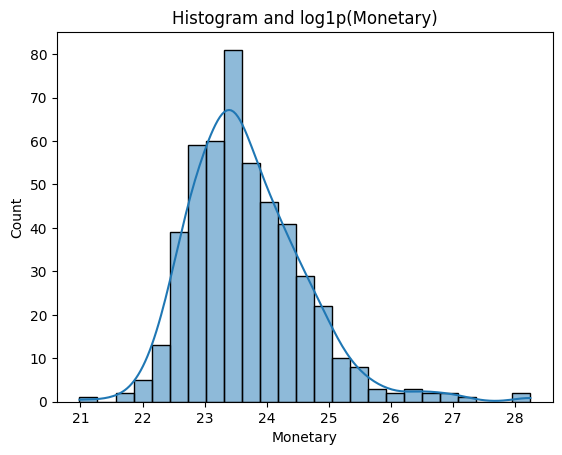

In [31]:
# Task 2.1: distribution of log1p(Monetary)
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
sns.histplot(data=X, x='Monetary', kde=True)
ax.set_title('Histogram and log1p(Monetary)')

## Task 2.2 - Agglomerative clustering (Ward, Euclidean)

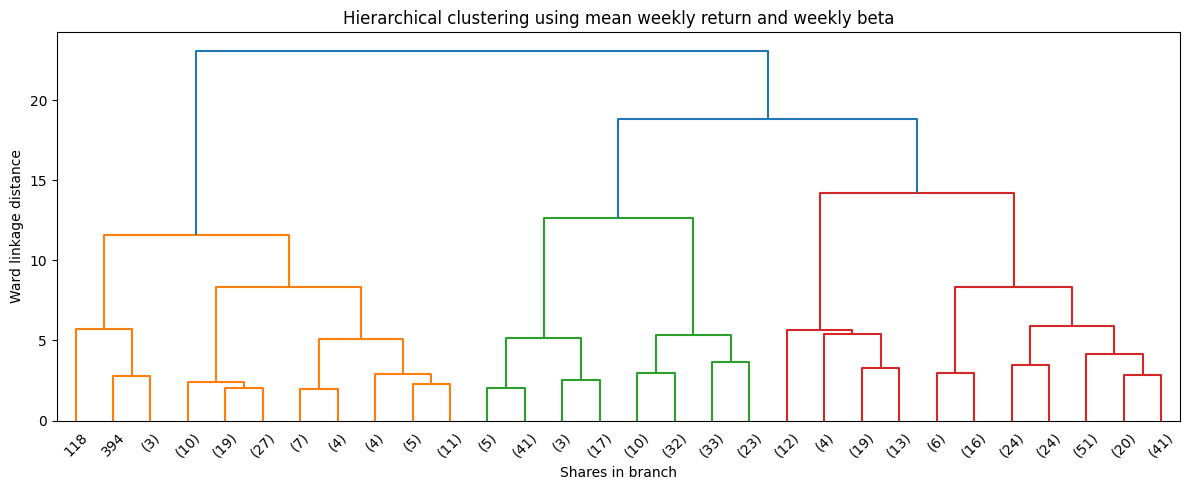

In [32]:
# Task 2.2: Ward dendrogram - risk and return
# Hierarchical clustering using Ward linkage.
hierarchy_rr = linkage(X_rr_scaled, method="ward")

# Draw the dendrogram.
plt.figure(figsize=(12, 5))
dendrogram(
    hierarchy_rr,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45
)
plt.title("Hierarchical clustering using mean weekly return and weekly beta")
plt.xlabel("Shares in branch")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.savefig("return_beta_dendrogram.png", dpi=150)
plt.show()

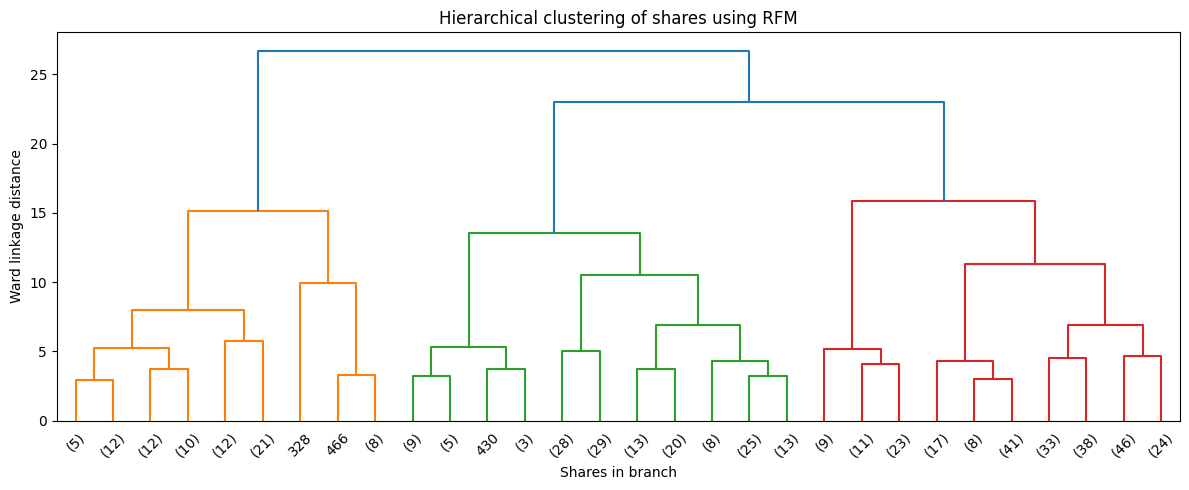

In [33]:
# Task 2.2: Ward dendrogram - RFM
# Ward linkage groups shares using Euclidean distance.
hierarchy = linkage(X_scaled, method="ward")

# Display the clustering tree.
plt.figure(figsize=(12, 5))
dendrogram(
    hierarchy,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45
)
plt.title("Hierarchical clustering of shares using RFM")
plt.xlabel("Shares in branch")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.savefig("rfm_dendrogram.png", dpi=150)
plt.show()

In [34]:
# Task 2.2: Ward cluster counts 2 to 8 - silhouette score and cluster sizes
results = []

for k in range(2, 9):
    data["Cluster"] = cut_tree(hierarchy_rr, n_clusters=k).ravel() + 1
    sizes = data.groupby("Cluster")["Share"].count()
    results.append({"Matrix": "Risk and return", "k": k, "Silhouette": round(silhouette_score(X_rr_scaled, data["Cluster"]), 3),
                    "Smallest cluster": int(sizes.min()), "Cluster sizes": sizes.tolist()})

    data["Cluster"] = cut_tree(hierarchy, n_clusters=k).ravel() + 1
    sizes = data.groupby("Cluster")["Share"].count()
    results.append({"Matrix": "RFM", "k": k, "Silhouette": round(silhouette_score(X_scaled, data["Cluster"]), 3),
                    "Smallest cluster": int(sizes.min()), "Cluster sizes": sizes.tolist()})

ward_comparison = pd.DataFrame(results, columns=["Matrix", "k", "Silhouette", "Smallest cluster", "Cluster sizes"])
ward_comparison.to_csv("ward_k_comparison.csv", index=False)
ward_comparison

,Matrix,k,Silhouette,Smallest cluster,Cluster sizes
0,Risk and return,2,0.339,92,"[394, 92]"
1,RFM,2,0.368,82,"[404, 82]"
2,Risk and return,3,0.274,92,"[230, 92, 164]"
3,RFM,3,0.304,82,"[250, 154, 82]"
4,Risk and return,4,0.282,48,"[182, 92, 164, 48]"
5,RFM,4,0.289,43,"[207, 154, 82, 43]"
6,Risk and return,5,0.304,48,"[182, 92, 98, 48, 66]"
7,RFM,5,0.305,10,"[207, 154, 72, 43, 10]"
8,Risk and return,6,0.320,5,"[182, 87, 98, 48, 66, 5]"
9,RFM,6,0.314,10,"[207, 18, 136, 72, 43, 10]"


In [35]:
# Task 2.2: Ward cluster averages in original units for each cluster count
for k in range(2, 9):
    data["Cluster"] = cut_tree(hierarchy_rr, n_clusters=k).ravel() + 1
    print('Ward, risk and return, k =', k)
    print(data.groupby("Cluster")[features_rr].mean().round(5))
    print()

for k in range(2, 9):
    data["Cluster"] = cut_tree(hierarchy, n_clusters=k).ravel() + 1
    print('Ward, RFM, k =', k)
    print(data.groupby("Cluster")[features].mean().round(2))
    print()

Ward, risk and return, k = 2
         Mean_Weekly_Return     Beta
Cluster                             
1                   0.00205  0.89795
2                   0.00632  1.29808

Ward, risk and return, k = 3
         Mean_Weekly_Return     Beta
Cluster                             
1                   0.00146  1.10956
2                   0.00632  1.29808
3                   0.00287  0.60118

Ward, risk and return, k = 4
         Mean_Weekly_Return     Beta
Cluster                             
1                   0.00132  0.97284
2                   0.00632  1.29808
3                   0.00287  0.60118
4                   0.00200  1.62796

Ward, risk and return, k = 5
         Mean_Weekly_Return     Beta
Cluster                             
1                   0.00132  0.97284
2                   0.00632  1.29808
3                   0.00422  0.71043
4                   0.00200  1.62796
5                   0.00088  0.43897

Ward, risk and return, k = 6
         Mean_Weekly_Return     Beta


## Task 2.3 - K-means (seed, multiple initialisations, k = 2..8)

In [36]:
# Task 2.3: K-means cluster counts 2 to 8 - inertia, silhouette score and cluster sizes (fixed seed, 10 initialisations)
results = []
sse_rr = {}
sse = {}

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_rr_scaled)
    sse_rr[k] = kmeans.inertia_ # SSE to closest cluster centroid
    data["Cluster"] = kmeans.labels_
    sizes = data.groupby("Cluster")["Share"].count()
    results.append({"Matrix": "Risk and return", "k": k, "Inertia": round(kmeans.inertia_, 2),
                    "Silhouette": round(silhouette_score(X_rr_scaled, kmeans.labels_), 3), "Smallest cluster": int(sizes.min()), "Cluster sizes": sizes.tolist()})

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    sse[k] = kmeans.inertia_ # SSE to closest cluster centroid
    data["Cluster"] = kmeans.labels_
    sizes = data.groupby("Cluster")["Share"].count()
    results.append({"Matrix": "RFM", "k": k, "Inertia": round(kmeans.inertia_, 2),
                    "Silhouette": round(silhouette_score(X_scaled, kmeans.labels_), 3), "Smallest cluster": int(sizes.min()), "Cluster sizes": sizes.tolist()})

kmeans_comparison = pd.DataFrame(results, columns=["Matrix", "k", "Inertia", "Silhouette", "Smallest cluster", "Cluster sizes"])
kmeans_comparison.to_csv("kmeans_k_comparison.csv", index=False)
kmeans_comparison

,Matrix,k,Inertia,Silhouette,Smallest cluster,Cluster sizes
0,Risk and return,2,621.63,0.387,143,"[143, 343]"
1,RFM,2,1066.83,0.423,68,"[418, 68]"
2,Risk and return,3,461.18,0.329,119,"[119, 202, 165]"
3,RFM,3,796.61,0.325,64,"[270, 64, 152]"
4,Risk and return,4,371.57,0.326,41,"[160, 41, 132, 153]"
5,RFM,4,609.83,0.341,61,"[92, 122, 61, 211]"
6,Risk and return,5,309.96,0.338,28,"[165, 114, 28, 124, 55]"
7,RFM,5,514.71,0.358,11,"[122, 87, 68, 198, 11]"
8,Risk and return,6,265.85,0.327,16,"[55, 137, 119, 81, 16, 78]"
9,RFM,6,437.42,0.346,11,"[120, 69, 104, 41, 11, 141]"


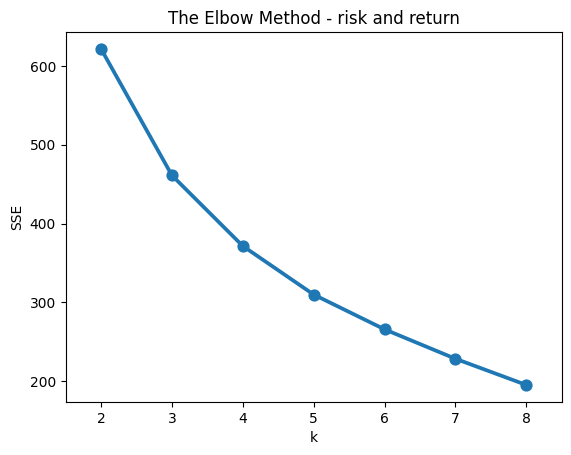

In [37]:
# Task 2.3: elbow plot - risk and return
plt.title('The Elbow Method - risk and return')
plt.xlabel('k')
plt.ylabel('SSE')
sns.pointplot(x=list(sse_rr.keys()), y=list(sse_rr.values()))
plt.savefig("elbow_return_beta.png", dpi=150)
plt.show()

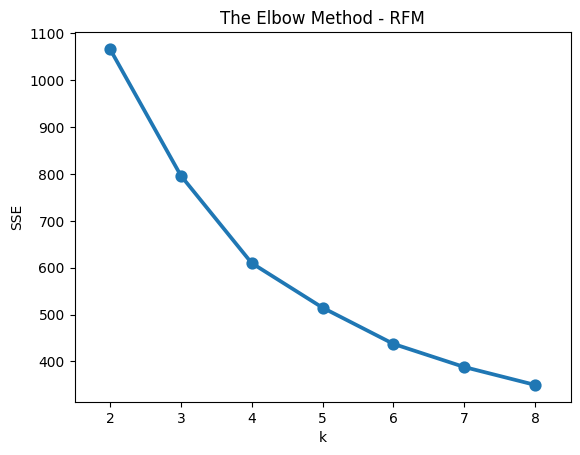

In [38]:
# Task 2.3: elbow plot - RFM
plt.title('The Elbow Method - RFM')
plt.xlabel('k')
plt.ylabel('SSE')
sns.pointplot(x=list(sse.keys()), y=list(sse.values()))
plt.savefig("elbow_rfm.png", dpi=150)
plt.show()

## Task 2.4 - Final four solutions, original-unit profiles, labelled plots, algorithm comparison
Selected cluster counts: 3 for all four solutions (chosen from the 2.2 and 2.3 tables; k = 2 has the highest silhouette but a single thin profile, k ≥ 5 produces 10-, 5- and 1-share clusters).

In [39]:
# Task 2.4: selected cluster counts and the four baseline solutions
# Selected cluster counts (see 2.2 and 2.3 tables)
k_ward_rr = 3
k_ward_rfm = 3
k_kmeans_rr = 3
k_kmeans_rfm = 3

# Final four baseline solutions
data["Ward_RR"] = cut_tree(hierarchy_rr, n_clusters=k_ward_rr).ravel() + 1
data["Ward_RFM"] = cut_tree(hierarchy, n_clusters=k_ward_rfm).ravel() + 1

model = KMeans(n_clusters=k_kmeans_rr, random_state=42, n_init=10)
model.fit(X_rr_scaled)
data["KMeans_RR"] = model.labels_ + 1

model = KMeans(n_clusters=k_kmeans_rfm, random_state=42, n_init=10)
model.fit(X_scaled)
data["KMeans_RFM"] = model.labels_ + 1

data.to_csv("feature_table_with_clusters.csv", index=False)
data[["Share", "Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM"]].head()

,Share,Ward_RR,KMeans_RR,Ward_RFM,KMeans_RFM
0,A,1,3,1,1
1,AAPL,2,1,2,3
2,ABBV,3,2,2,3
3,ABNB,1,3,2,3
4,ABT,3,2,2,3


In [40]:
# Task 2.4: risk and return cluster profiles in original units
for solution in ["Ward_RR", "KMeans_RR"]:
    print(solution)
    print(data.groupby(solution).agg({
        'Mean_Weekly_Return':['mean', 'median'],
        'Beta':['mean', 'median', 'count']}).round(5))
    print()

Ward_RR
        Mean_Weekly_Return              Beta               
                      mean   median     mean   median count
Ward_RR                                                    
1                  0.00146  0.00171  1.10956  1.03841   230
2                  0.00632  0.00550  1.29808  1.21771    92
3                  0.00287  0.00327  0.60118  0.57770   164

KMeans_RR
          Mean_Weekly_Return              Beta               
                        mean   median     mean   median count
KMeans_RR                                                    
1                    0.00596  0.00528  1.32640  1.22144   119
2                    0.00259  0.00259  0.63082  0.62154   202
3                    0.00095  0.00118  1.13909  1.08053   165



In [41]:
# Task 2.4: RFM cluster profiles in original units
for solution in ["Ward_RFM", "KMeans_RFM"]:
    print(solution)
    print(data.groupby(solution).agg({
        'Recency':['mean', 'median'],
        'Frequency':['mean', 'median'],
        'Monetary':['mean', 'median', 'count']}).round(2))
    print()

Ward_RFM
         Recency        Frequency             Monetary                    
            mean median      mean median          mean        median count
Ward_RFM                                                                  
1          12.12   11.0      3.36    3.0  1.176413e+10  1.117761e+10   250
2          13.68   11.0      2.86    3.0  8.014525e+10  3.969545e+10   154
3           58.3   54.5      2.10    2.0  4.715898e+10  1.784903e+10    82

KMeans_RFM
           Recency        Frequency             Monetary                    
              mean median      mean median          mean        median count
KMeans_RFM                                                                  
1            13.37   11.0      3.35    3.0  1.201394e+10  1.137067e+10   270
2            64.61   55.0      1.69    2.0  5.443512e+10  2.114736e+10    64
3             14.3   11.0      2.89    3.0  8.172911e+10  4.160242e+10   152



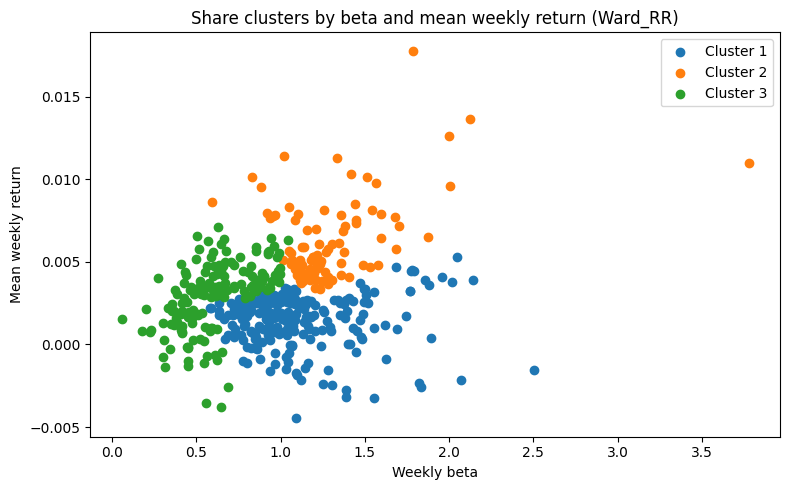

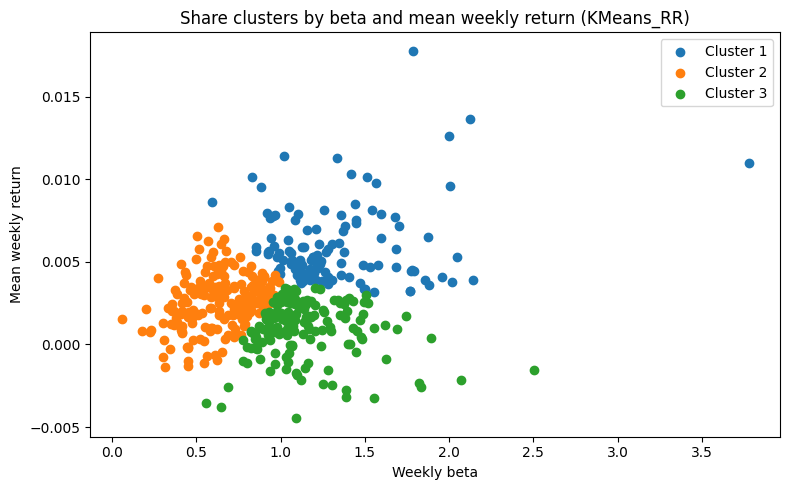

In [42]:
# Task 2.4: risk and return clusters plotted in original units
for solution in ["Ward_RR", "KMeans_RR"]:
    plt.figure(figsize=(8, 5))

    for cluster, group in data.groupby(solution):
        plt.scatter(group["Beta"], group["Mean_Weekly_Return"], label=f"Cluster {cluster}")

    plt.xlabel("Weekly beta")
    plt.ylabel("Mean weekly return")
    plt.title("Share clusters by beta and mean weekly return (" + solution + ")")
    plt.legend()
    plt.tight_layout()
    plt.savefig("scatter_" + solution + ".png", dpi=150)
    plt.show()

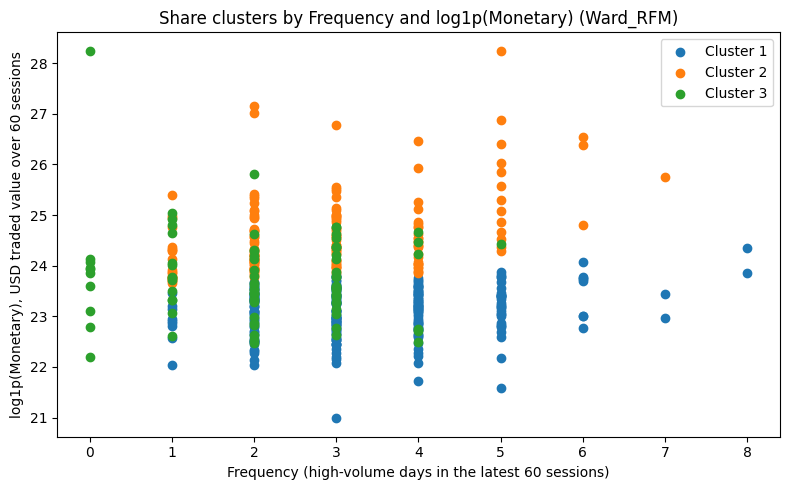

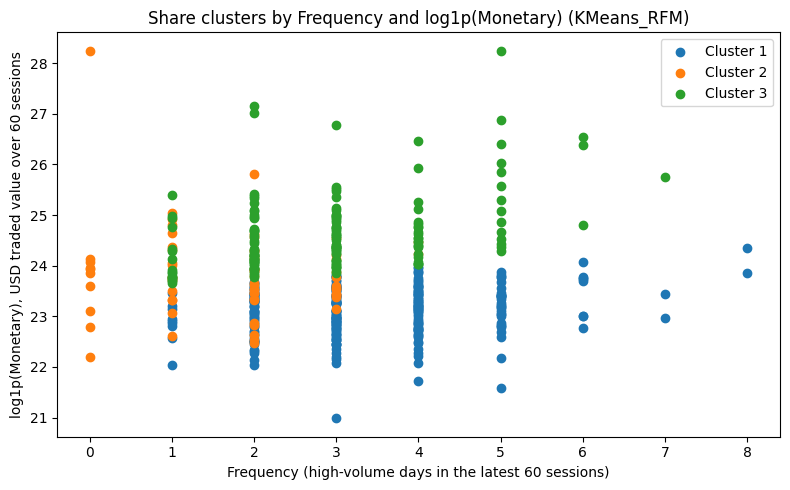

In [43]:
# Task 2.4: RFM clusters plotted - Frequency against log1p(Monetary)
for solution in ["Ward_RFM", "KMeans_RFM"]:
    plt.figure(figsize=(8, 5))

    for cluster, group in data.groupby(solution):
        plt.scatter(group["Frequency"], np.log1p(group["Monetary"]), label=f"Cluster {cluster}")

    plt.xlabel("Frequency (high-volume days in the latest 60 sessions)")
    plt.ylabel("log1p(Monetary), USD traded value over 60 sessions")
    plt.title("Share clusters by Frequency and log1p(Monetary) (" + solution + ")")
    plt.legend()
    plt.tight_layout()
    plt.savefig("scatter_" + solution + ".png", dpi=150)
    plt.show()

In [44]:
# Task 2.4: compare Ward and K-means on the same shares - membership counts and adjusted Rand index
print(data.groupby(['Ward_RR', 'KMeans_RR'])["Share"].count())
print('Adjusted Rand index (Ward vs K-means, risk and return):', round(adjusted_rand_score(data["Ward_RR"], data["KMeans_RR"]), 3))
print()
print(data.groupby(['Ward_RFM', 'KMeans_RFM'])["Share"].count())
print('Adjusted Rand index (Ward vs K-means, RFM):', round(adjusted_rand_score(data["Ward_RFM"], data["KMeans_RFM"]), 3))

Ward_RR  KMeans_RR
1        1             16
         2             54
         3            160
2        1             90
         3              2
3        1             13
         2            148
         3              3
Name: Share, dtype: int64
Adjusted Rand index (Ward vs K-means, risk and return): 0.516

Ward_RFM  KMeans_RFM
1         1             250
2         1               5
          2               5
          3             144
3         1              15
          2              59
          3               8
Name: Share, dtype: int64
Adjusted Rand index (Ward vs K-means, RFM): 0.834


## Task 2.5 - RFM sensitivity and correlated inputs

In [45]:
# Task 2.5.1: correlations among Recency, Frequency and log1p(Monetary)
import pandas as pd
import numpy as np

features = data[["Recency", "Frequency", "Monetary"]].dropna().copy()

features["LogMonetary"] = np.log1p(features["Monetary"])

print("Correlations among the clustering inputs:")
print(
    features[["Recency", "Frequency", "LogMonetary"]]
    .corr()
    .round(2)
)
features[["Recency", "Frequency", "LogMonetary"]].corr().round(4).to_csv("rfm_correlations.csv")

Correlations among the clustering inputs:
             Recency  Frequency  LogMonetary
Recency         1.00      -0.35         0.15
Frequency      -0.35       1.00         0.01
LogMonetary     0.15       0.01         1.00


In [46]:
# Task 2.5.2: remove Monetary - Ward on Recency and Frequency only, same shares and cluster count; adjusted Rand index and traded-value profiles
features_rf = ["Recency", "Frequency"]

X_rf = data[features_rf].copy()
X_rf_scaled = StandardScaler().fit_transform(X_rf)

hierarchy_rf = linkage(X_rf_scaled, method="ward")

data["Ward_RF"] = cut_tree(hierarchy_rf, n_clusters=k_ward_rfm).ravel() + 1

print("Shares:", len(data), "| k:", k_ward_rfm)
print("Adjusted Rand index (Ward RFM vs Ward RF):", round(adjusted_rand_score(data["Ward_RFM"], data["Ward_RF"]), 3))

print("Cluster averages in original units - with Monetary (Ward_RFM):")
print(data.groupby("Ward_RFM")[["Recency", "Frequency", "Monetary"]].mean().round(2))
print("\nCluster averages in original units - without Monetary (Ward_RF):")
print(data.groupby("Ward_RF")[["Recency", "Frequency", "Monetary"]].mean().round(2))
print("\nMembership counts Ward_RFM vs Ward_RF:")
print(data.groupby(['Ward_RFM', 'Ward_RF'])["Share"].count())

data.to_csv("feature_table_with_clusters.csv", index=False)

Shares: 486 | k: 3
Adjusted Rand index (Ward RFM vs Ward RF): 0.291
Cluster averages in original units - with Monetary (Ward_RFM):
          Recency  Frequency      Monetary
Ward_RFM                                  
1           12.12       3.36  1.176413e+10
2           13.68       2.86  8.014525e+10
3            58.3       2.10  4.715898e+10

Cluster averages in original units - without Monetary (Ward_RF):
         Recency  Frequency      Monetary
Ward_RF                                  
1          11.04       1.80  3.433790e+10
2          12.88       3.86  3.940097e+10
3          56.56       2.01  4.652963e+10

Membership counts Ward_RFM vs Ward_RF:
Ward_RFM  Ward_RF
1         1           66
          2          183
          3            1
2         1           59
          2           86
          3            9
3         2            3
          3           79
Name: Share, dtype: int64


## Task 3 - supporting outputs for the data mart proposal (3.1) and the review of results (3.2)

In [47]:
# Task 3: profiles of every cluster solution on all five features
for solution in ["Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM"]:
    print(solution)
    print(data.groupby(solution).agg({
        'Mean_Weekly_Return': 'mean',
        'Beta': 'mean',
        'Recency': 'mean',
        'Frequency': 'mean',
        'Monetary': ['mean', 'count']}).round(4))
    print()

Ward_RR
        Mean_Weekly_Return    Beta  Recency Frequency      Monetary      
                      mean    mean     mean      mean          mean count
Ward_RR                                                                  
1                   0.0015  1.1096  18.9304    3.0565  3.380100e+10   230
2                   0.0063  1.2981  23.6739    3.1957  7.878092e+10    92
3                   0.0029  0.6012  20.6463    2.7805  2.517294e+10   164

KMeans_RR
          Mean_Weekly_Return    Beta  Recency Frequency      Monetary      
                        mean    mean     mean      mean          mean count
KMeans_RR                                                                  
1                     0.0060  1.3264  23.6891    3.1008  8.703662e+10   119
2                     0.0026  0.6308  19.9307    2.9109  2.343970e+10   202
3                     0.0009  1.1391  18.6242    3.0061  2.459552e+10   165

Ward_RFM
         Mean_Weekly_Return    Beta  Recency Frequency      Monetary   

In [48]:
# Task 3: sector composition of each cluster
for solution in ["Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM"]:
    sector_table = data.groupby([solution, 'GICS Sector'])["Share"].count()
    sector_table.to_csv("sector_composition_" + solution + ".csv")
    print(solution)
    print(sector_table)
    print()

Ward_RR
Ward_RR  GICS Sector           
1        Communication Services     7
         Consumer Discretionary    27
         Consumer Staples           5
         Financials                31
         Health Care               29
         Industrials               44
         Information Technology    43
         Materials                 16
         Real Estate               23
         Utilities                  5
2        Communication Services     5
         Consumer Discretionary    11
         Energy                     4
         Financials                13
         Health Care                2
         Industrials               21
         Information Technology    29
         Materials                  3
         Real Estate                3
         Utilities                  1
3        Communication Services     8
         Consumer Discretionary     9
         Consumer Staples          27
         Energy                    16
         Financials                30
         H

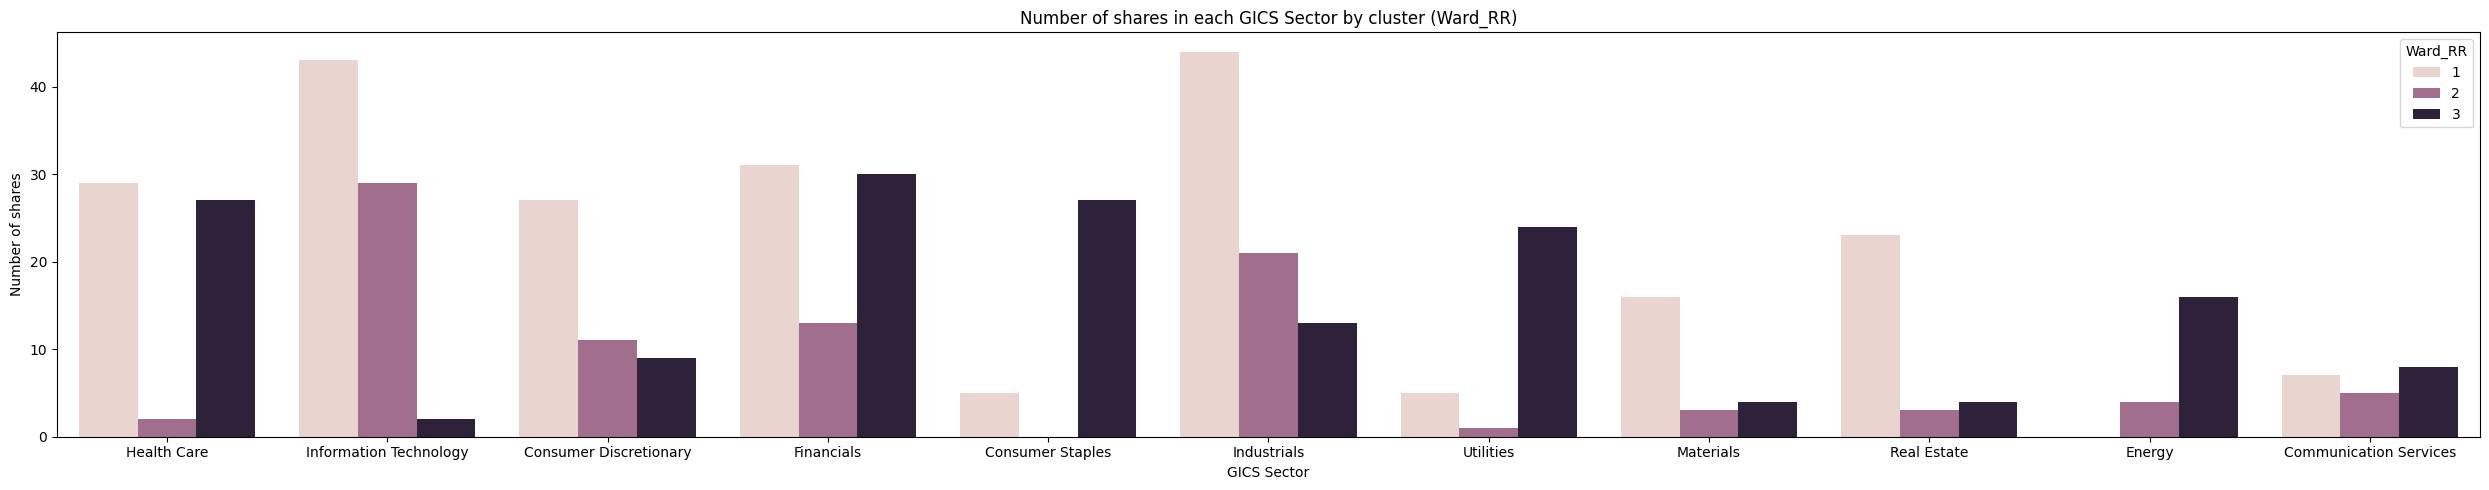

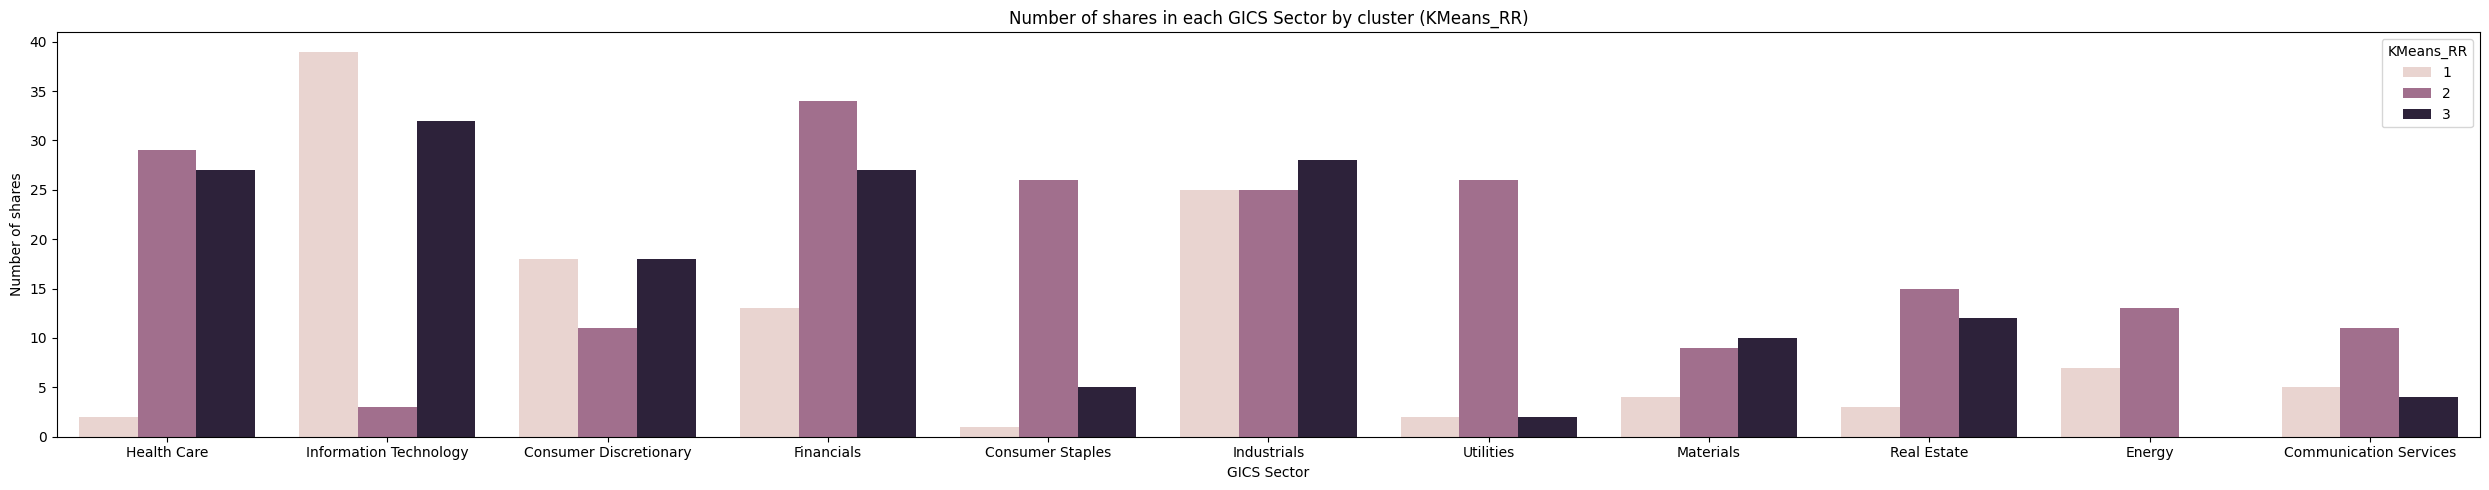

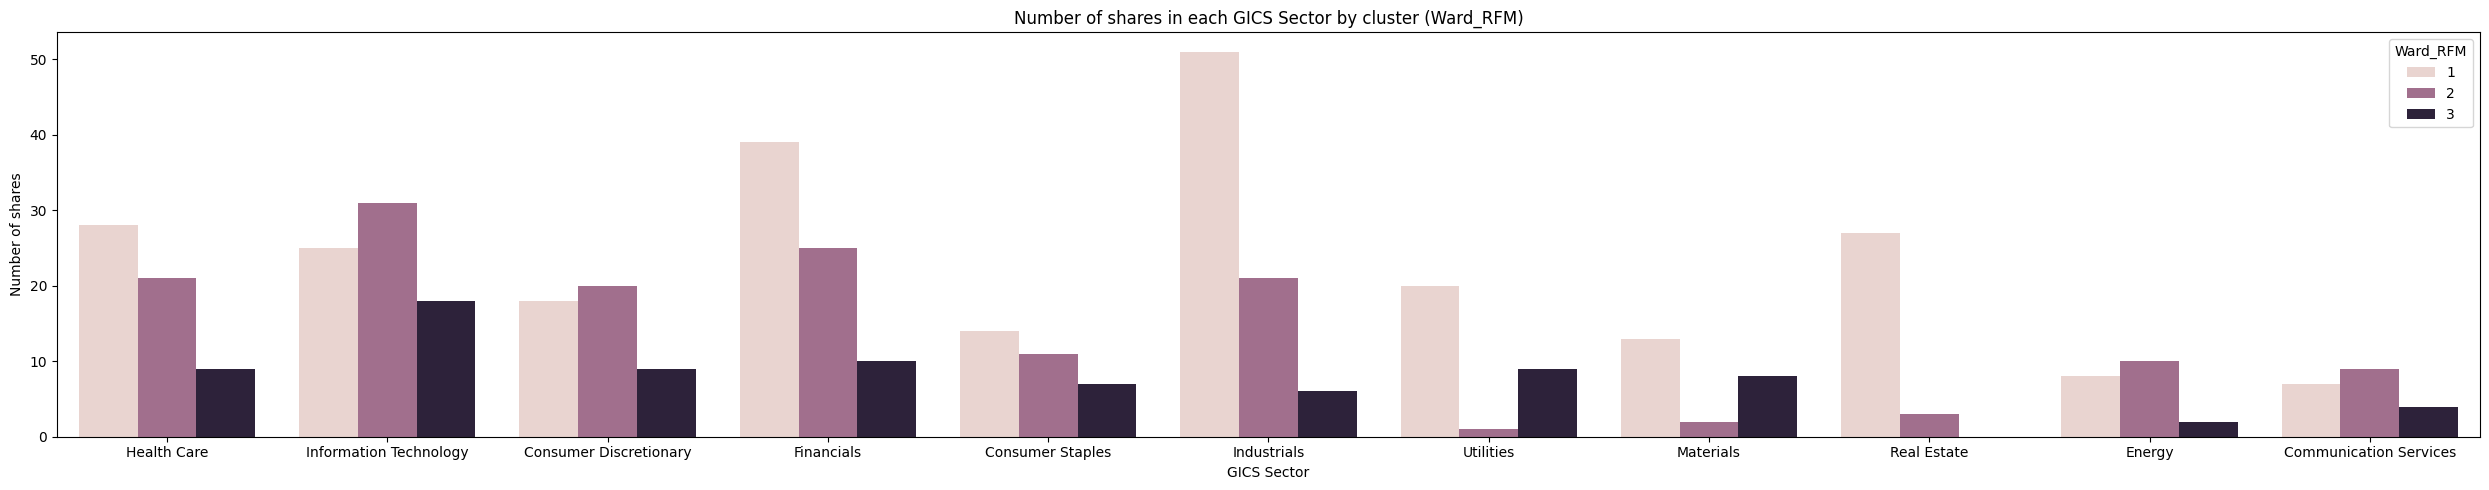

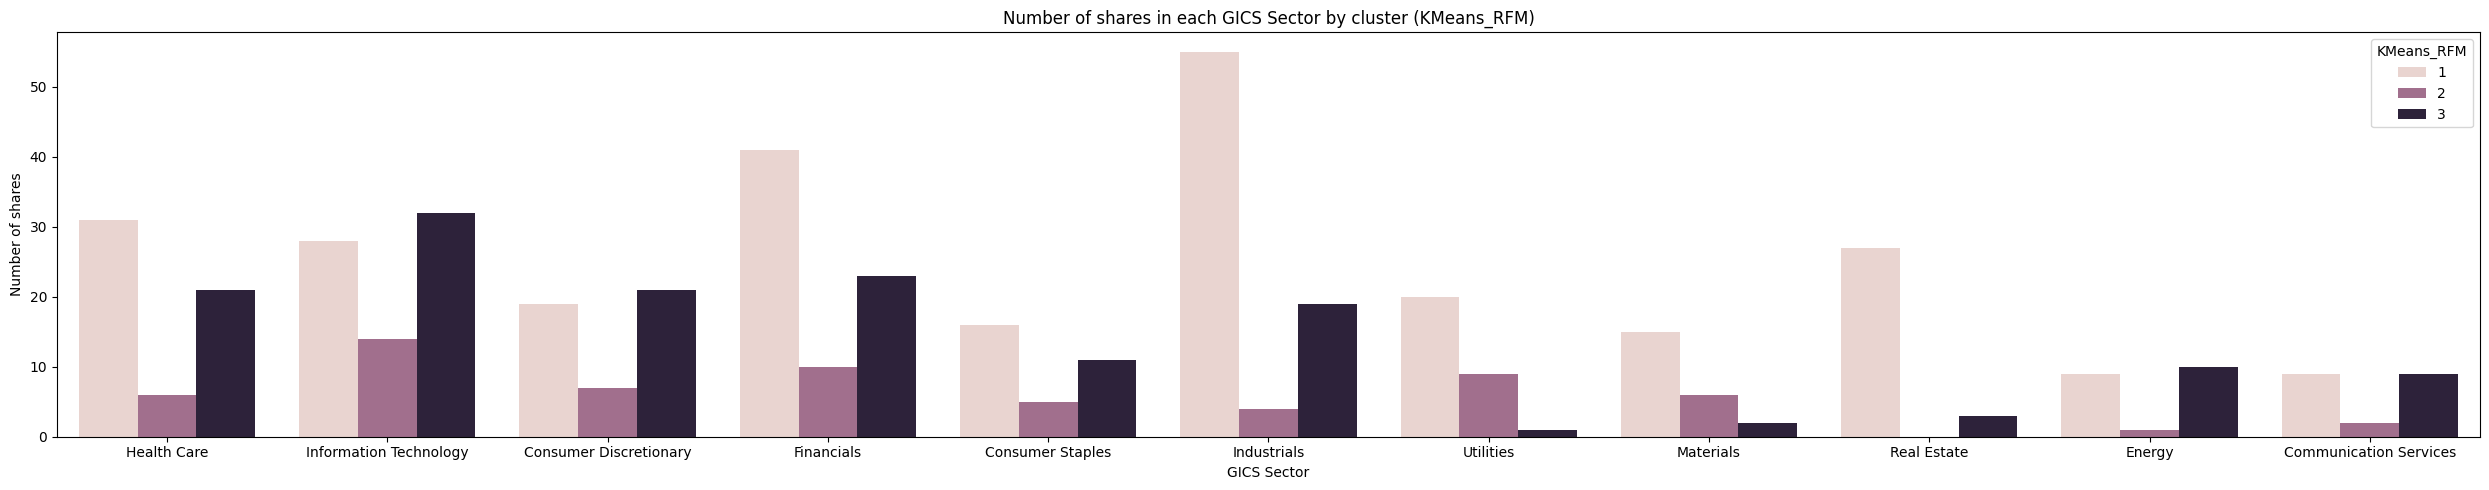

In [49]:
# Task 3: sector composition charts
for solution in ["Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM"]:
    f, ax = plt.subplots(figsize=(25, 5))
    ax = sns.countplot(x="GICS Sector", hue=solution, data=data)
    ax.set_title("Number of shares in each GICS Sector by cluster (" + solution + ")")
    ax.set_xlabel("GICS Sector")
    ax.set_ylabel("Number of shares")
    plt.tight_layout()
    plt.savefig("sectors_" + solution + ".png", dpi=150)
    plt.show()

In [50]:
# Task 3: calculation log - sources, windows, observation date, settings and cluster counts of this run
run_log = pd.Series({
    "Ticker source": source_metadata["ticker_list"],
    "Price source": source_metadata["prices"],
    "Retrieval date": source_metadata["retrieved_date"],
    "Study period": start + " to " + end + " (end exclusive)",
    "Observation date": str(observation_date.date()),
    "Weekly returns": "W-FRI, last price in week, adjusted close",
    "Weeks of returns": int(weekly_obs.max()),
    "RFM window": "60 trading sessions",
    "High-volume rule": "volume > 2 x mean of preceding 20 sessions",
    "Shares retained": len(shares),
    "Shares in common set": len(data),
    "k Ward risk and return": k_ward_rr,
    "k Ward RFM": k_ward_rfm,
    "k K-means risk and return": k_kmeans_rr,
    "k K-means RFM": k_kmeans_rfm,
    "K-means random_state": 42,
    "K-means n_init": 10
}, name="Value")
run_log.to_csv("run_log.csv")
run_log

,Value
Ticker source,https://en.wikipedia.org/wiki/List_of_S%26P_50...
Price source,Yahoo Finance via yfinance
Retrieval date,2026-11-24
Study period,2021-01-01 to 2025-01-01 (end exclusive)
Observation date,2024-12-31
Weekly returns,"W-FRI, last price in week, adjusted close"
Weeks of returns,207
RFM window,60 trading sessions
High-volume rule,volume > 2 x mean of preceding 20 sessions
Shares retained,486


In [51]:
# Task 3: average pairwise correlation of weekly returns (return dependencies)
return_correlations = weekly_returns[data["Share"].tolist()].corr()
n = len(return_correlations)
average_correlation = (return_correlations.sum().sum() - n) / (n * (n - 1))

print('Average pairwise correlation of weekly returns:', round(average_correlation, 3))
print('Shares with positive beta:', int((data["Beta"] > 0).sum()), 'of', len(data))

Average pairwise correlation of weekly returns: 0.3
Shares with positive beta: 486 of 486
